# Tugas Single Layer Perceptron (SLP) 
**Nama:** Muhammad Zaki Wiryawan (26/590720/SPA/01259)

**Mata Kuliah:** Kecerdasan Buatan Lanjut  
**Dataset:** Iris Dataset (`Iris-setosa` = 0 vs `Iris-versicolor` = 1)  
**Metode:** Single Layer Perceptron (SLP) dengan fungsi aktivasi Sigmoid dan optimasi Stochastic Gradient Descent (SGD)

---
### Spesifikasi Tugas & Pembagian Data:
1. **Target:** Setosa = `0`, Versicolor = `1`
2. **Learning Rate (\(\eta\)):** `0.1`
3. **Bobot Awal:** `bias = 0.5`, `teta1 = 0.5`, `teta2 = 0.5`, `teta3 = 0.5`, `teta4 = 0.5`
4. **Epoch:** 5 Epoch
5. **Data Split (80 Training / 20 Validation):**
   - **Training (80 sampel):** 40 Setosa pertama (No 1-40) + 40 Versicolor pertama (No 51-90)
   - **Validation (20 sampel):** 10 Setosa terakhir (No 41-50) + 10 Versicolor terakhir (No 91-100)




In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

try:
    from IPython.display import display
except ImportError:
    display = print

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Library berhasil diimpor dan opsi display diset untuk menampilkan tabel penuh!")


Library berhasil diimpor dan opsi display diset untuk menampilkan tabel penuh!


In [ ]:
# 1. Load dataset Iris dari file CSV
df_raw = pd.read_csv('PMM-TemplateSLP.xlsx - Data.csv', header=None, names=['X1', 'X2', 'X3', 'X4', 'Species'])

# 2. Encode target: Iris-setosa = 0, Iris-versicolor = 1
df_raw['TARGET'] = df_raw['Species'].map({'Iris-setosa': 0, 'Iris-versicolor': 1})

# 3. Stratified Split 80 Training & 20 Validation 
train_indices = list(range(0, 40)) + list(range(50, 90))
val_indices = list(range(40, 50)) + list(range(90, 100))

train_df = df_raw.iloc[train_indices].reset_index(drop=True)
val_df = df_raw.iloc[val_indices].reset_index(drop=True)

X_train = train_df[['X1', 'X2', 'X3', 'X4']].values.astype(float)
y_train = train_df['TARGET'].values.astype(float)

X_val = val_df[['X1', 'X2', 'X3', 'X4']].values.astype(float)
y_val = val_df['TARGET'].values.astype(float)

print(f"Total Dataset: {len(df_raw)} sampel")
print(f"Data Training: {len(X_train)} sampel (Setosa: {sum(y_train==0)}, Versicolor: {sum(y_train==1)})")
print(f"Data Validation: {len(X_val)} sampel (Setosa: {sum(y_val==0)}, Versicolor: {sum(y_val==1)})")


Total Dataset: 100 sampel
Data Training: 80 sampel (Setosa: 40, Versicolor: 40)
Data Validation: 20 sampel (Setosa: 10, Versicolor: 10)


In [ ]:
# Fungsi aktivasi Sigmoid
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

# Hyperparameter
lr = 0.1
num_epochs = 5
b = 0.5
theta = np.array([0.5, 0.5, 0.5, 0.5], dtype=float)

history = []
train_epoch_logs = []
val_epoch_logs = []

print(f"Inisialisasi Bobot Awal: bias = {b}, theta = {theta}, Learning Rate = {lr}\n")

for epoch in range(1, num_epochs + 1):
    epoch_sample_logs = []
    tr_losses = []
    tr_preds = []
    
    #  TRAINING PHASE
    for i in range(len(X_train)):
        xi = X_train[i]
        yi = y_train[i]
        
        # 1. Forward pass
        zi = b + np.dot(xi, theta)
        gz = sigmoid(zi)
        pred = 1 if gz > 0.5 else 0
        err = gz - yi
        sse = err ** 2
        
        tr_losses.append(sse)
        tr_preds.append(pred)
        
        # 2. Gradients
        dbias = 2.0 * (gz - yi) * (1.0 - gz) * gz
        dtheta = dbias * xi
        
        
        epoch_sample_logs.append({
            'EPOCH': f"epoch {epoch}",
            'No': i + 1,
            'X1': xi[0], 'X2': xi[1], 'X3': xi[2], 'X4': xi[3],
            'TARGET': int(yi),
            'bias': b, 'teta1': theta[0], 'teta2': theta[1], 'teta 3': theta[2], 'teta4': theta[3],
            'z': zi, 'g(z)': gz, 'Prediksi': pred, 'error': err, 'Sum Square Error': sse,
            'dbias': dbias, 'dteta1': dtheta[0], 'dteta2': dtheta[1], 'dteta3': dtheta[2], 'dteta4': dtheta[3]
        })
        
        # 3. Update bobot (SGD)
        b = b - lr * dbias
        theta = theta - lr * dtheta
        
    train_loss = np.mean(tr_losses)
    train_acc = np.mean(np.array(tr_preds) == y_train)
    train_epoch_logs.append(epoch_sample_logs)
    
    #  VALIDATION PHASE 
    val_sample_logs = []
    val_losses = []
    val_preds = []
    
    # Validasi menggunakan bobot hasil training 
    for i in range(len(X_val)):
        xi = X_val[i]
        yi = y_val[i]
        zi = b + np.dot(xi, theta)
        gz = sigmoid(zi)
        pred = 1 if gz > 0.5 else 0
        err = gz - yi
        sse = err ** 2
        val_losses.append(sse)
        val_preds.append(pred)
        
        val_sample_logs.append({
            'EPOCH': f"epoch {epoch}",
            'No': i + 1,
            'X1': xi[0], 'X2': xi[1], 'X3': xi[2], 'X4': xi[3],
            'TARGET': int(yi),
            'bias': b, 'teta1': theta[0], 'teta2': theta[1], 'teta 3': theta[2], 'teta4': theta[3],
            'z': zi, 'g(z)': gz, 'Prediksi': pred, 'error': err, 'Sum Square Error': sse
        })
        
    val_loss = np.mean(val_losses)
    val_acc = np.mean(np.array(val_preds) == y_val)
    val_epoch_logs.append(val_sample_logs)
    
    history.append({
        'Epoch': epoch,
        'Train Loss': train_loss,
        'Train Accuracy': train_acc,
        'Validation Loss': val_loss,
        'Validation Accuracy': val_acc,
        'End Bias': b,
        'End Theta1': theta[0],
        'End Theta2': theta[1],
        'End Theta3': theta[2],
        'End Theta4': theta[3]
    })
    
    print(f"Epoch {epoch}/5 Selesai:")
    print(f"  Train Loss: {train_loss:.6f} | Train Acc: {train_acc*100:.2f}%")
    print(f"  Val Loss:   {val_loss:.6f} | Val Acc:   {val_acc*100:.2f}%")
    print(f"  Bobot Akhir: bias = {b:.6f}, theta = {np.round(theta, 6)}\n")


Inisialisasi Bobot Awal: bias = 0.5, theta = [0.5 0.5 0.5 0.5], Learning Rate = 0.1

Epoch 1/5 Selesai:
  Train Loss: 0.449889 | Train Acc: 52.50%
  Val Loss:   0.328951 | Val Acc:   50.00%
  Bobot Akhir: bias = 0.380336, theta = [-0.019133 0.071447 0.524449 0.551140]

Epoch 2/5 Selesai:
  Train Loss: 0.037452 | Train Acc: 95.00%
  Val Loss:   0.247289 | Val Acc:   50.00%
  Bobot Akhir: bias = 0.342472, theta = [-0.093195 -0.076158 0.707221 0.636439]

Epoch 3/5 Selesai:
  Train Loss: 0.024372 | Train Acc: 97.50%
  Val Loss:   0.175892 | Val Acc:   50.00%
  Bobot Akhir: bias = 0.310418, theta = [-0.152266 -0.203786 0.865711 0.709340]

Epoch 4/5 Selesai:
  Train Loss: 0.017357 | Train Acc: 97.50%
  Val Loss:   0.119381 | Val Acc:   85.00%
  Bobot Akhir: bias = 0.282274, theta = [-0.201860 -0.318152 1.002541 0.770788]

Epoch 5/5 Selesai:
  Train Loss: 0.012740 | Train Acc: 98.75%
  Val Loss:   0.081581 | Val Acc:   100.00%
  Bobot Akhir: bias = 0.257720, theta = [-0.241802 -0.416903 1.122

In [4]:
# TABEL RINGKASAN EPOCH 1 - 5 (TRAINING & VALIDATION)
summary_df = pd.DataFrame(history)
disp_summary = summary_df[['Epoch', 'Train Loss', 'Validation Loss', 'Train Accuracy', 'Validation Accuracy', 'End Bias', 'End Theta1', 'End Theta2', 'End Theta3', 'End Theta4']].copy()
disp_summary['Train Accuracy'] = (disp_summary['Train Accuracy'] * 100).map(lambda x: f"{x:.2f}%")
disp_summary['Validation Accuracy'] = (disp_summary['Validation Accuracy'] * 100).map(lambda x: f"{x:.2f}%")

print("=== TABEL RINGKASAN SEMUA EPOCH (IDENTIK GSHEET & EXCEL) ===")
display(disp_summary)


=== TABEL RINGKASAN SEMUA EPOCH (IDENTIK GSHEET & EXCEL) ===


Epoch,Train Loss,Validation Loss,Train Accuracy,Validation Accuracy,End Bias,End Theta1,End Theta2,End Theta3,End Theta4
1,0.449889,0.328951,52.50%,50.00%,0.380336,-0.019133,0.071447,0.524449,0.551140
2,0.037452,0.247289,95.00%,50.00%,0.342472,-0.093195,-0.076158,0.707221,0.636439
3,0.024372,0.175892,97.50%,50.00%,0.310418,-0.152266,-0.203786,0.865711,0.709340
4,0.017357,0.119381,97.50%,85.00%,0.282274,-0.201860,-0.318152,1.002541,0.770788
5,0.012740,0.081581,98.75%,100.00%,0.257720,-0.241802,-0.416903,1.122214,0.824059


## 1. TABEL HASIL VALIDASI LENGKAP PER EPOCH 

In [ ]:
for ep in range(1, 6):
    df_val_ep = pd.DataFrame(val_epoch_logs[ep - 1])
    avg_loss = summary_df.loc[summary_df['Epoch'] == ep, 'Validation Loss'].values[0]
    acc = summary_df.loc[summary_df['Epoch'] == ep, 'Validation Accuracy'].values[0] * 100
    
    print("=" * 115)
    print(f"                      TABEL VALIDASI EPOCH {ep} (LENGKAP SEMUA SAMPEL NO 1 - 20)")
    print(f"           Rata-rata Loss (Mean SSE): {avg_loss:.6f}  |  Akurasi Validasi: {acc:.2f}%")
    print("=" * 115)
    display(df_val_ep)
    print("\n")


                      TABEL VALIDASI EPOCH 1 (LENGKAP SEMUA SAMPEL NO 1 - 20)
           Rata-rata Loss (Mean SSE): 0.328951  |  Akurasi Validasi: 50.00%


EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta 3,teta4,z,g(z),Prediksi,error,Sum Square Error
epoch 1,1,5.0,3.5,1.3,0.3,0,0.380336,-0.019133,0.071447,0.524449,0.55114,1.381860,0.799289,1,0.799289,0.638864
epoch 1,2,4.5,2.3,1.3,0.3,0,0.380336,-0.019133,0.071447,0.524449,0.55114,1.305690,0.786791,1,0.786791,0.619040
epoch 1,3,4.4,3.2,1.3,0.2,0,0.380336,-0.019133,0.071447,0.524449,0.55114,1.316792,0.788647,1,0.788647,0.621965
epoch 1,4,5.0,3.5,1.6,0.6,0,0.380336,-0.019133,0.071447,0.524449,0.55114,1.704536,0.846126,1,0.846126,0.715930
epoch 1,5,5.1,3.8,1.9,0.4,0,0.380336,-0.019133,0.071447,0.524449,0.55114,1.771164,0.854602,1,0.854602,0.730345
epoch 1,6,4.8,3.0,1.4,0.3,0,0.380336,-0.019133,0.071447,0.524449,0.55114,1.402408,0.802566,1,0.802566,0.644112
epoch 1,7,5.1,3.8,1.6,0.2,0,0.380336,-0.019133,0.071447,0.524449,0.55114,1.503601,0.818111,1,0.818111,0.669306
epoch 1,8,4.6,3.2,1.4,0.2,0,0.380336,-0.019133,0.071447,0.524449,0.55114,1.365410,0.796638,1,0.796638,0.634631
epoch 1,9,5.3,3.7,1.5,0.2,0,0.380336,-0.019133,0.071447,0.524449,0.55114,1.440185,0.808483,1,0.808483,0.653645
epoch 1,10,5.0,3.3,1.4,0.2,0,0.380336,-0.019133,0.071447,0.524449,0.55114,1.364901,0.796555,1,0.796555,0.634500


                      TABEL VALIDASI EPOCH 2 (LENGKAP SEMUA SAMPEL NO 1 - 20)
           Rata-rata Loss (Mean SSE): 0.247289  |  Akurasi Validasi: 50.00%


EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta 3,teta4,z,g(z),Prediksi,error,Sum Square Error
epoch 2,1,5.0,3.5,1.3,0.3,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,0.720265,0.672665,1,0.672665,0.452479
epoch 2,2,4.5,2.3,1.3,0.3,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,0.858253,0.702295,1,0.702295,0.493219
epoch 2,3,4.4,3.2,1.3,0.2,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,0.735386,0.675986,1,0.675986,0.456957
epoch 2,4,5.0,3.5,1.6,0.6,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,1.123363,0.754612,1,0.754612,0.569439
epoch 2,5,5.1,3.8,1.9,0.4,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,1.176075,0.764241,1,0.764241,0.584065
epoch 2,6,4.8,3.0,1.4,0.3,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,0.847706,0.700086,1,0.700086,0.490120
epoch 2,7,5.1,3.8,1.6,0.2,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,0.836621,0.697753,1,0.697753,0.486859
epoch 2,8,4.6,3.2,1.4,0.2,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,0.787469,0.687288,1,0.687288,0.472364
epoch 2,9,5.3,3.7,1.5,0.2,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,0.754876,0.680240,1,0.680240,0.462727
epoch 2,10,5.0,3.3,1.4,0.2,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,0.742575,0.677559,1,0.677559,0.459086


                      TABEL VALIDASI EPOCH 3 (LENGKAP SEMUA SAMPEL NO 1 - 20)
           Rata-rata Loss (Mean SSE): 0.175892  |  Akurasi Validasi: 50.00%


EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta 3,teta4,z,g(z),Prediksi,error,Sum Square Error
epoch 3,1,5.0,3.5,1.3,0.3,0,0.310418,-0.152266,-0.203786,0.865711,0.70934,0.174062,0.543406,1,0.543406,0.295290
epoch 3,2,4.5,2.3,1.3,0.3,0,0.310418,-0.152266,-0.203786,0.865711,0.70934,0.494739,0.621222,1,0.621222,0.385917
epoch 3,3,4.4,3.2,1.3,0.2,0,0.310418,-0.152266,-0.203786,0.865711,0.70934,0.255624,0.563560,1,0.563560,0.317600
epoch 3,4,5.0,3.5,1.6,0.6,0,0.310418,-0.152266,-0.203786,0.865711,0.70934,0.646577,0.656239,1,0.656239,0.430649
epoch 3,5,5.1,3.8,1.9,0.4,0,0.310418,-0.152266,-0.203786,0.865711,0.70934,0.688060,0.665535,1,0.665535,0.442937
epoch 3,6,4.8,3.0,1.4,0.3,0,0.310418,-0.152266,-0.203786,0.865711,0.70934,0.392980,0.597000,1,0.597000,0.356409
epoch 3,7,5.1,3.8,1.6,0.2,0,0.310418,-0.152266,-0.203786,0.865711,0.70934,0.286479,0.571134,1,0.571134,0.326194
epoch 3,8,4.6,3.2,1.4,0.2,0,0.310418,-0.152266,-0.203786,0.865711,0.70934,0.311742,0.577310,1,0.577310,0.333287
epoch 3,9,5.3,3.7,1.5,0.2,0,0.310418,-0.152266,-0.203786,0.865711,0.70934,0.189833,0.547316,1,0.547316,0.299555
epoch 3,10,5.0,3.3,1.4,0.2,0,0.310418,-0.152266,-0.203786,0.865711,0.70934,0.230457,0.557361,1,0.557361,0.310651


                      TABEL VALIDASI EPOCH 4 (LENGKAP SEMUA SAMPEL NO 1 - 20)
           Rata-rata Loss (Mean SSE): 0.119381  |  Akurasi Validasi: 85.00%


EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta 3,teta4,z,g(z),Prediksi,error,Sum Square Error
epoch 4,1,5.0,3.5,1.3,0.3,0,0.282274,-0.20186,-0.318152,1.002541,0.770788,-0.306017,0.424087,0,0.424087,0.179850
epoch 4,2,4.5,2.3,1.3,0.3,0,0.282274,-0.20186,-0.318152,1.002541,0.770788,0.176695,0.544059,1,0.544059,0.296000
epoch 4,3,4.4,3.2,1.3,0.2,0,0.282274,-0.20186,-0.318152,1.002541,0.770788,-0.166534,0.458462,0,0.458462,0.210188
epoch 4,4,5.0,3.5,1.6,0.6,0,0.282274,-0.20186,-0.318152,1.002541,0.770788,0.225981,0.556256,1,0.556256,0.309421
epoch 4,5,5.1,3.8,1.9,0.4,0,0.282274,-0.20186,-0.318152,1.002541,0.770788,0.256955,0.563888,1,0.563888,0.317969
epoch 4,6,4.8,3.0,1.4,0.3,0,0.282274,-0.20186,-0.318152,1.002541,0.770788,-0.006315,0.498421,0,0.498421,0.248424
epoch 4,7,5.1,3.8,1.6,0.2,0,0.282274,-0.20186,-0.318152,1.002541,0.770788,-0.197965,0.450670,0,0.450670,0.203103
epoch 4,8,4.6,3.2,1.4,0.2,0,0.282274,-0.20186,-0.318152,1.002541,0.770788,-0.106652,0.473362,0,0.473362,0.224072
epoch 4,9,5.3,3.7,1.5,0.2,0,0.282274,-0.20186,-0.318152,1.002541,0.770788,-0.306776,0.423902,0,0.423902,0.179693
epoch 4,10,5.0,3.3,1.4,0.2,0,0.282274,-0.20186,-0.318152,1.002541,0.770788,-0.219211,0.445416,0,0.445416,0.198395


                      TABEL VALIDASI EPOCH 5 (LENGKAP SEMUA SAMPEL NO 1 - 20)
           Rata-rata Loss (Mean SSE): 0.081581  |  Akurasi Validasi: 100.00%


EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta 3,teta4,z,g(z),Prediksi,error,Sum Square Error
epoch 5,1,5.0,3.5,1.3,0.3,0,0.25772,-0.241802,-0.416903,1.122214,0.824059,-0.704355,0.330847,0,0.330847,0.109460
epoch 5,2,4.5,2.3,1.3,0.3,0,0.25772,-0.241802,-0.416903,1.122214,0.824059,-0.083170,0.479219,0,0.479219,0.229651
epoch 5,3,4.4,3.2,1.3,0.2,0,0.25772,-0.241802,-0.416903,1.122214,0.824059,-0.516609,0.373646,0,0.373646,0.139611
epoch 5,4,5.0,3.5,1.6,0.6,0,0.25772,-0.241802,-0.416903,1.122214,0.824059,-0.120473,0.469918,0,0.469918,0.220823
epoch 5,5,5.1,3.8,1.9,0.4,0,0.25772,-0.241802,-0.416903,1.122214,0.824059,-0.097872,0.475551,0,0.475551,0.226149
epoch 5,6,4.8,3.0,1.4,0.3,0,0.25772,-0.241802,-0.416903,1.122214,0.824059,-0.335322,0.416946,0,0.416946,0.173844
epoch 5,7,5.1,3.8,1.6,0.2,0,0.25772,-0.241802,-0.416903,1.122214,0.824059,-0.599348,0.354493,0,0.354493,0.125665
epoch 5,8,4.6,3.2,1.4,0.2,0,0.25772,-0.241802,-0.416903,1.122214,0.824059,-0.452748,0.388708,0,0.388708,0.151094
epoch 5,9,5.3,3.7,1.5,0.2,0,0.25772,-0.241802,-0.416903,1.122214,0.824059,-0.718239,0.327781,0,0.327781,0.107440
epoch 5,10,5.0,3.3,1.4,0.2,0,0.25772,-0.241802,-0.416903,1.122214,0.824059,-0.591159,0.356369,0,0.356369,0.126999


## 2. TABEL HASIL TRAINING PER EPOCH 

In [ ]:
for ep in range(1, 6):
    df_tr_ep = pd.DataFrame(train_epoch_logs[ep - 1])
    avg_loss = summary_df.loc[summary_df['Epoch'] == ep, 'Train Loss'].values[0]
    acc = summary_df.loc[summary_df['Epoch'] == ep, 'Train Accuracy'].values[0] * 100
    
    print("=" * 125)
    print(f"                      TABEL TRAINING EPOCH {ep} (SAMPEL NO 1 - 20 DARI 80 SAMPEL)")
    print(f"           Rata-rata Loss (Mean SSE): {avg_loss:.6f}  |  Akurasi Training: {acc:.2f}%")
    print("=" * 125)
    display(df_tr_ep.head(20))
    print(f"* Catatan: Menampilkan 20 baris pertama dari total 80 sampel pada Epoch {ep}. Gunakan df_tr_all_epoch_{ep} untuk melihat seluruh 80 baris.\n\n")


                      TABEL TRAINING EPOCH 1 (SAMPEL NO 1 - 20 DARI 80 SAMPEL)
           Rata-rata Loss (Mean SSE): 0.449889  |  Akurasi Training: 52.50%


EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta 3,teta4,z,g(z),Prediksi,error,Sum Square Error,dbias,dteta1,dteta2,dteta3,dteta4
epoch 1,1,5.1,3.5,1.4,0.2,0,0.500000,0.500000,0.500000,0.500000,0.500000,5.600000,0.996316,1,0.996316,0.992645,0.007314,0.037303,0.025600,0.010240,0.001463
epoch 1,2,4.9,3.0,1.4,0.2,0,0.499269,0.496270,0.497440,0.498976,0.499854,5.221847,0.994632,1,0.994632,0.989292,0.010622,0.052047,0.031865,0.014870,0.002124
epoch 1,3,4.7,3.2,1.3,0.2,0,0.498206,0.491065,0.494253,0.497489,0.499641,5.134487,0.994144,1,0.994144,0.988323,0.011574,0.054400,0.037038,0.015047,0.002315
epoch 1,4,4.6,3.1,1.5,0.2,0,0.497049,0.485625,0.490550,0.495984,0.499410,5.095487,0.993913,1,0.993913,0.987863,0.012026,0.055321,0.037282,0.018040,0.002405
epoch 1,5,5.0,3.6,1.4,0.2,0,0.495846,0.480093,0.486821,0.494180,0.499169,5.440555,0.995682,1,0.995682,0.991382,0.008562,0.042811,0.030824,0.011987,0.001712
epoch 1,6,5.4,3.9,1.7,0.4,0,0.494990,0.475812,0.483739,0.492982,0.498998,5.988624,0.997499,1,0.997499,0.995005,0.004977,0.026874,0.019409,0.008460,0.001991
epoch 1,7,4.6,3.4,1.4,0.3,0,0.494492,0.473124,0.481798,0.492136,0.498799,5.147608,0.994220,1,0.994220,0.988474,0.011426,0.052560,0.038849,0.015997,0.003428
epoch 1,8,5.0,3.4,1.5,0.2,0,0.493350,0.467868,0.477913,0.490536,0.498456,5.293092,0.994999,1,0.994999,0.990023,0.009902,0.049512,0.033668,0.014853,0.001980
epoch 1,9,4.4,2.9,1.4,0.2,0,0.492360,0.462917,0.474546,0.489051,0.498258,4.689702,0.990894,1,0.990894,0.981871,0.017881,0.078678,0.051856,0.025034,0.003576
epoch 1,10,4.9,3.1,1.5,0.1,0,0.490571,0.455049,0.469361,0.486547,0.497900,4.954943,0.993001,1,0.993001,0.986051,0.013803,0.067635,0.042789,0.020705,0.001380


* Catatan: Menampilkan 20 baris pertama dari total 80 sampel pada Epoch 1. Gunakan df_tr_all_epoch_1 untuk melihat seluruh 80 baris.




                      TABEL TRAINING EPOCH 2 (SAMPEL NO 1 - 20 DARI 80 SAMPEL)
           Rata-rata Loss (Mean SSE): 0.037452  |  Akurasi Training: 95.00%


EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta 3,teta4,z,g(z),Prediksi,error,Sum Square Error,dbias,dteta1,dteta2,dteta3,dteta4
epoch 2,1,5.1,3.5,1.4,0.2,0,0.380336,-0.019133,0.071447,0.524449,0.551140,1.377277,0.798553,1,0.798553,0.637687,0.256920,1.310292,0.899220,0.359688,0.051384
epoch 2,2,4.9,3.0,1.4,0.2,0,0.354644,-0.150162,-0.018475,0.488481,0.546002,0.356496,0.588192,1,0.588192,0.345970,0.284946,1.396237,0.854839,0.398925,0.056989
epoch 2,3,4.7,3.2,1.3,0.2,0,0.326149,-0.289786,-0.103959,0.448588,0.540303,-0.677289,0.336867,0,0.336867,0.113479,0.150504,0.707367,0.481611,0.195655,0.030101
epoch 2,4,4.6,3.1,1.5,0.2,0,0.311099,-0.360523,-0.152120,0.429023,0.537293,-1.067886,0.255805,0,0.255805,0.065436,0.097395,0.448016,0.301924,0.146092,0.019479
epoch 2,5,5.0,3.6,1.4,0.2,0,0.301360,-0.405324,-0.182313,0.414413,0.535345,-1.694340,0.155206,0,0.155206,0.024089,0.040700,0.203501,0.146521,0.056980,0.008140
epoch 2,6,5.4,3.9,1.7,0.4,0,0.297290,-0.425674,-0.196965,0.408715,0.534531,-1.860887,0.134600,0,0.134600,0.018117,0.031357,0.169328,0.122293,0.053307,0.012543
epoch 2,7,4.6,3.4,1.4,0.3,0,0.294154,-0.442607,-0.209194,0.403385,0.533277,-1.728378,0.150795,0,0.150795,0.022739,0.038620,0.177654,0.131310,0.054069,0.011586
epoch 2,8,5.0,3.4,1.5,0.2,0,0.290292,-0.460373,-0.222325,0.397978,0.532118,-2.064086,0.112637,0,0.112637,0.012687,0.022516,0.112580,0.076554,0.033774,0.004503
epoch 2,9,4.4,2.9,1.4,0.2,0,0.288040,-0.471631,-0.229981,0.394600,0.531668,-1.795304,0.142424,0,0.142424,0.020284,0.034791,0.153080,0.100894,0.048707,0.006958
epoch 2,10,4.9,3.1,1.5,0.1,0,0.284561,-0.486939,-0.240070,0.389730,0.530972,-2.207964,0.099038,0,0.099038,0.009808,0.017674,0.086603,0.054790,0.026511,0.001767


* Catatan: Menampilkan 20 baris pertama dari total 80 sampel pada Epoch 2. Gunakan df_tr_all_epoch_2 untuk melihat seluruh 80 baris.




... (5 outputs left out)

* Catatan: Menampilkan 20 baris pertama dari total 80 sampel pada Epoch 4. Gunakan df_tr_all_epoch_4 untuk melihat seluruh 80 baris.




                      TABEL TRAINING EPOCH 5 (SAMPEL NO 1 - 20 DARI 80 SAMPEL)
           Rata-rata Loss (Mean SSE): 0.012740  |  Akurasi Training: 98.75%


EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta 3,teta4,z,g(z),Prediksi,error,Sum Square Error,dbias,dteta1,dteta2,dteta3,dteta4
epoch 5,1,5.1,3.5,1.4,0.2,0,0.282274,-0.201860,-0.318152,1.002541,0.770788,-0.303028,0.424817,0,0.424817,0.180470,0.207606,1.058792,0.726622,0.290649,0.041521
epoch 5,2,4.9,3.0,1.4,0.2,0,0.261513,-0.307739,-0.390814,0.973476,0.766636,-0.902657,0.288505,0,0.288505,0.083235,0.118443,0.580369,0.355328,0.165820,0.023689
epoch 5,3,4.7,3.2,1.3,0.2,0,0.249669,-0.365776,-0.426347,0.956894,0.764267,-1.436972,0.192015,0,0.192015,0.036870,0.059580,0.280027,0.190657,0.077454,0.011916
epoch 5,4,4.6,3.1,1.5,0.2,0,0.243711,-0.393779,-0.445412,0.949149,0.763075,-1.372112,0.202279,0,0.202279,0.040917,0.065280,0.300289,0.202369,0.097920,0.013056
epoch 5,5,5.0,3.6,1.4,0.2,0,0.237183,-0.423808,-0.465649,0.939357,0.761770,-2.090740,0.110000,0,0.110000,0.012100,0.021538,0.107690,0.077537,0.030153,0.004308
epoch 5,6,5.4,3.9,1.7,0.4,0,0.235029,-0.434577,-0.473403,0.936341,0.761339,-2.061641,0.112881,0,0.112881,0.012742,0.022608,0.122082,0.088170,0.038433,0.009043
epoch 5,7,4.6,3.4,1.4,0.3,0,0.232768,-0.446785,-0.482220,0.932498,0.760434,-1.928362,0.126932,0,0.126932,0.016112,0.028133,0.129413,0.095653,0.039387,0.008440
epoch 5,8,5.0,3.4,1.5,0.2,0,0.229955,-0.459726,-0.491785,0.928559,0.759590,-2.195989,0.100111,0,0.100111,0.010022,0.018038,0.090189,0.061329,0.027057,0.003608
epoch 5,9,4.4,2.9,1.4,0.2,0,0.228151,-0.468745,-0.497918,0.925854,0.759230,-1.830249,0.138209,0,0.138209,0.019102,0.032923,0.144862,0.095477,0.046093,0.006585
epoch 5,10,4.9,3.1,1.5,0.1,0,0.224859,-0.483231,-0.507466,0.921244,0.758571,-2.258395,0.094628,0,0.094628,0.008954,0.016214,0.079449,0.050264,0.024321,0.001621


* Catatan: Menampilkan 20 baris pertama dari total 80 sampel pada Epoch 5. Gunakan df_tr_all_epoch_5 untuk melihat seluruh 80 baris.




## 3. TABEL GABUNGAN SEMUA EPOCH 




In [ ]:
df_all_validation = pd.concat([pd.DataFrame(logs) for logs in val_epoch_logs], ignore_index=True)

df_all_training = pd.concat([pd.DataFrame(logs) for logs in train_epoch_logs], ignore_index=True)

print(f"Ukuran Tabel Gabungan Validasi: {df_all_validation.shape} (100 baris, {df_all_validation.shape[1]} kolom)")
print(f"Ukuran Tabel Gabungan Training: {df_all_training.shape} (400 baris, {df_all_training.shape[1]} kolom)\n")

print("=== CONTOH TAMPILAN TABEL GABUNGAN VALIDASI (Sample Baris Pertama & Transisi Epoch) ===")

display(df_all_validation.iloc[[0, 1, 19, 20, 21, 39, 40]])


Ukuran Tabel Gabungan Validasi: (100, 17) (100 baris, 17 kolom)
Ukuran Tabel Gabungan Training: (400, 22) (400 baris, 22 kolom)

=== CONTOH TAMPILAN TABEL GABUNGAN VALIDASI (Sample Baris Pertama & Transisi Epoch) ===


EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta 3,teta4,z,g(z),Prediksi,error,Sum Square Error
epoch 1,1,5.0,3.5,1.3,0.3,0,0.380336,-0.019133,0.071447,0.524449,0.551140,1.381860,0.799289,1,0.799289,0.638864
epoch 1,2,4.5,2.3,1.3,0.3,0,0.380336,-0.019133,0.071447,0.524449,0.551140,1.305690,0.786791,1,0.786791,0.619040
epoch 1,20,5.7,2.8,4.1,1.3,1,0.380336,-0.019133,0.071447,0.524449,0.551140,3.338052,0.965711,1,-0.034289,0.001176
epoch 2,1,5.0,3.5,1.3,0.3,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,0.720265,0.672665,1,0.672665,0.452479
epoch 2,2,4.5,2.3,1.3,0.3,0,0.342472,-0.093195,-0.076158,0.707221,0.636439,0.858253,0.702295,1,0.702295,0.493219
epoch 2,20,5.7,2.8,4.1,1.3,1,0.342472,-0.093195,-0.076158,0.707221,0.636439,3.324999,0.965277,1,-0.034723,0.001206
epoch 3,1,5.0,3.5,1.3,0.3,0,0.310418,-0.152266,-0.203786,0.865711,0.709340,0.174062,0.543406,1,0.543406,0.295290


## 4. GRAFIK LAPORAN TUGAS (PAGE 2, 3, 4, DAN 5)



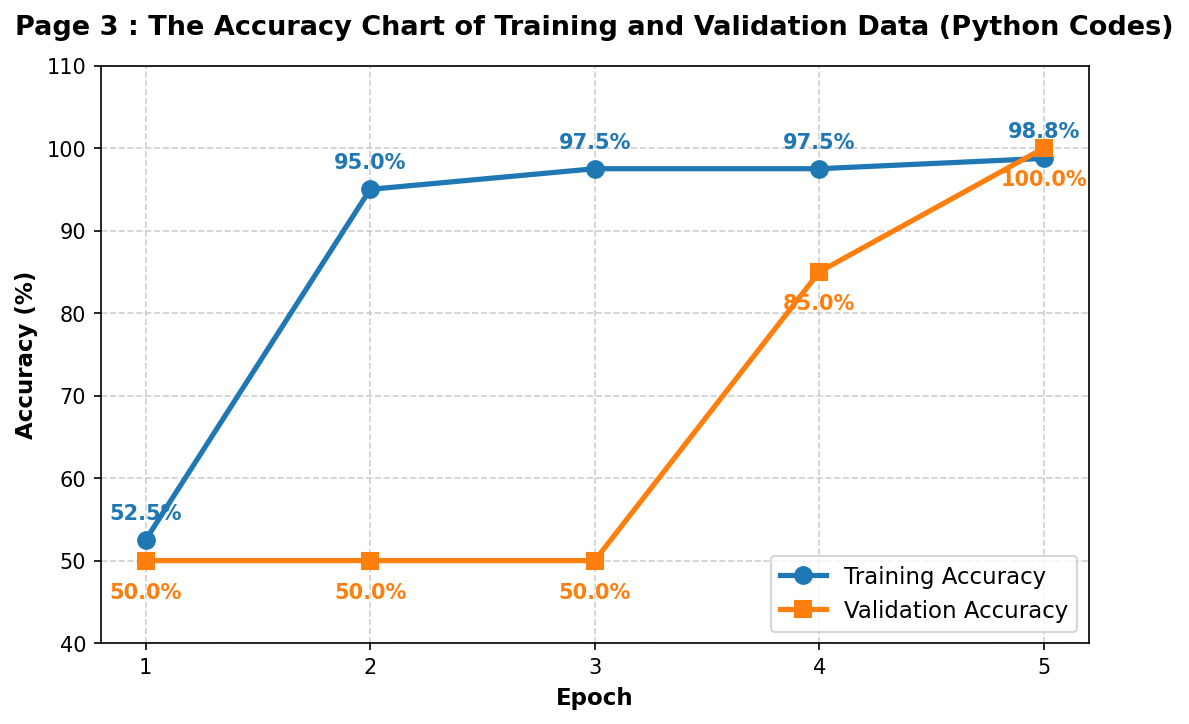

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
epochs = summary_df['Epoch'].values

ax.plot(epochs, summary_df['Train Accuracy'] * 100, marker='o', linewidth=2.5, markersize=8, color='#1f77b4', label='Training Accuracy')
ax.plot(epochs, summary_df['Validation Accuracy'] * 100, marker='s', linewidth=2.5, markersize=8, color='#ff7f0e', label='Validation Accuracy')

for _, row in summary_df.iterrows():
    ax.annotate(f"{row['Train Accuracy']*100:.1f}%", (row['Epoch'], row['Train Accuracy']*100), 
                textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10, fontweight='bold', color='#1f77b4')
    ax.annotate(f"{row['Validation Accuracy']*100:.1f}%", (row['Epoch'], row['Validation Accuracy']*100), 
                textcoords="offset points", xytext=(0, -18), ha='center', fontsize=10, fontweight='bold', color='#ff7f0e')

ax.set_title('Page 3 : The Accuracy Chart of Training and Validation Data\n(Obtained from Python Codes)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Epoch', fontsize=11, fontweight='bold')
ax.set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold')
ax.set_xticks(epochs)
ax.set_ylim(40, 110)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(fontsize=11, loc='lower right', frameon=True)

plt.tight_layout()
plt.savefig('page3_python_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()


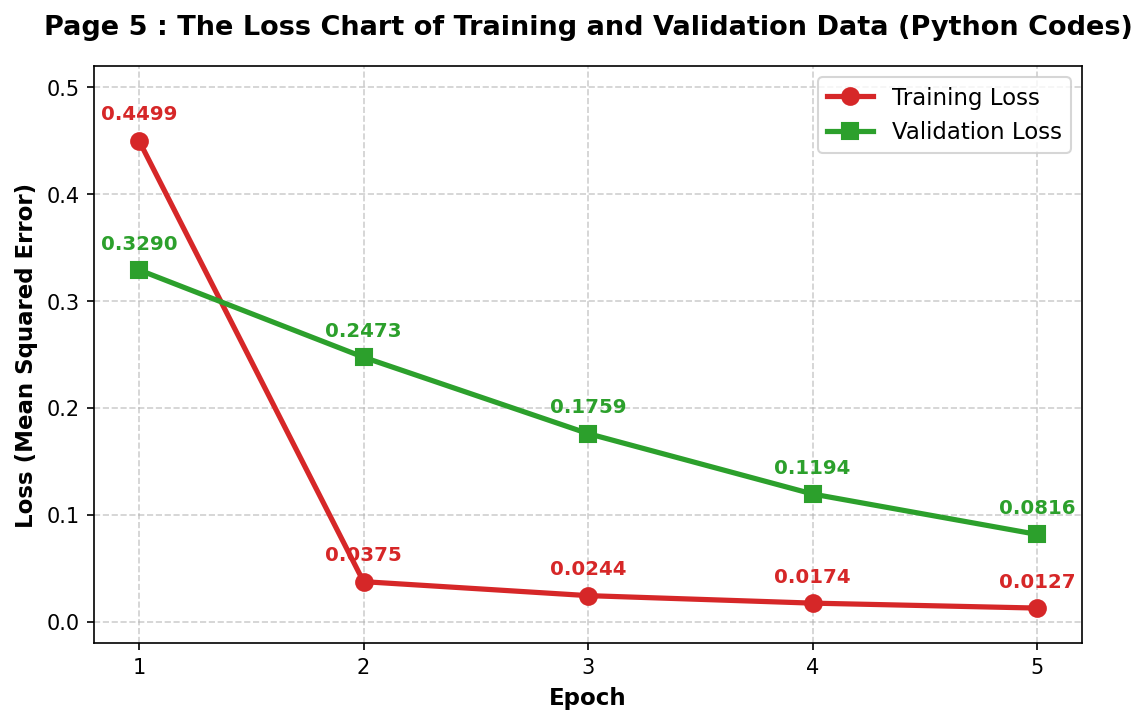

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))

ax.plot(epochs, summary_df['Train Loss'], marker='o', linewidth=2.5, markersize=8, color='#d62728', label='Training Loss')
ax.plot(epochs, summary_df['Validation Loss'], marker='s', linewidth=2.5, markersize=8, color='#2ca02c', label='Validation Loss')

for _, row in summary_df.iterrows():
    ax.annotate(f"{row['Train Loss']:.4f}", (row['Epoch'], row['Train Loss']), 
                textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9.5, fontweight='bold', color='#d62728')
    ax.annotate(f"{row['Validation Loss']:.4f}", (row['Epoch'], row['Validation Loss']), 
                textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9.5, fontweight='bold', color='#2ca02c')

ax.set_title('Page 5 : The Loss Chart of Training and Validation Data\n(Obtained from Python Codes)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Epoch', fontsize=11, fontweight='bold')
ax.set_ylabel('Loss (Mean Squared Error)', fontsize=11, fontweight='bold')
ax.set_xticks(epochs)
ax.set_ylim(-0.02, 0.52)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(fontsize=11, loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('page5_python_loss.png', dpi=300, bbox_inches='tight')
plt.show()


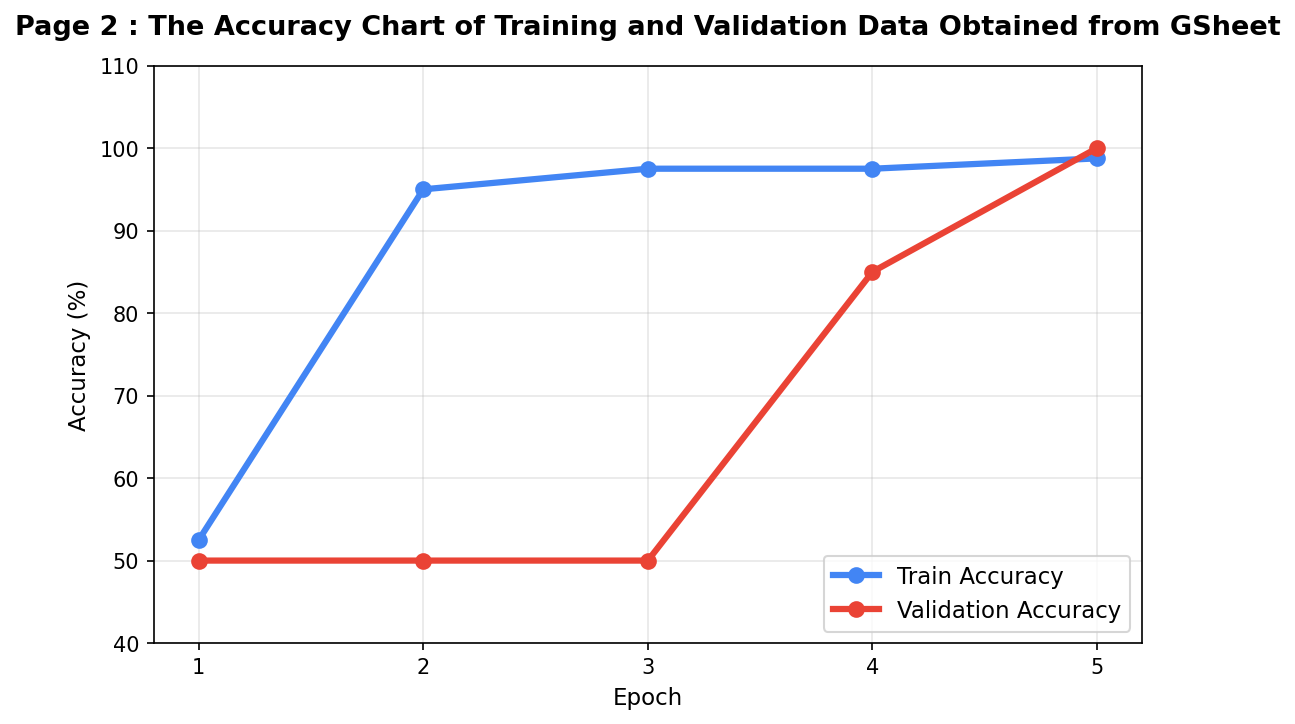

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5))

ax.plot(epochs, summary_df['Train Accuracy'] * 100, marker='o', linewidth=3, markersize=7, color='#4285F4', label='Train Accuracy')
ax.plot(epochs, summary_df['Validation Accuracy'] * 100, marker='o', linewidth=3, markersize=7, color='#EA4335', label='Validation Accuracy')

ax.set_title('Page 2 : The Accuracy Chart of Training and Validation Data\nObtained from GSheet / Spreadsheet', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Epoch', fontsize=11)
ax.set_ylabel('Accuracy (%)', fontsize=11)
ax.set_xticks(epochs)
ax.set_ylim(40, 110)
ax.grid(True, linestyle='-', alpha=0.3)
ax.legend(fontsize=11, loc='lower right')

plt.tight_layout()
plt.savefig('page2_gsheet_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()


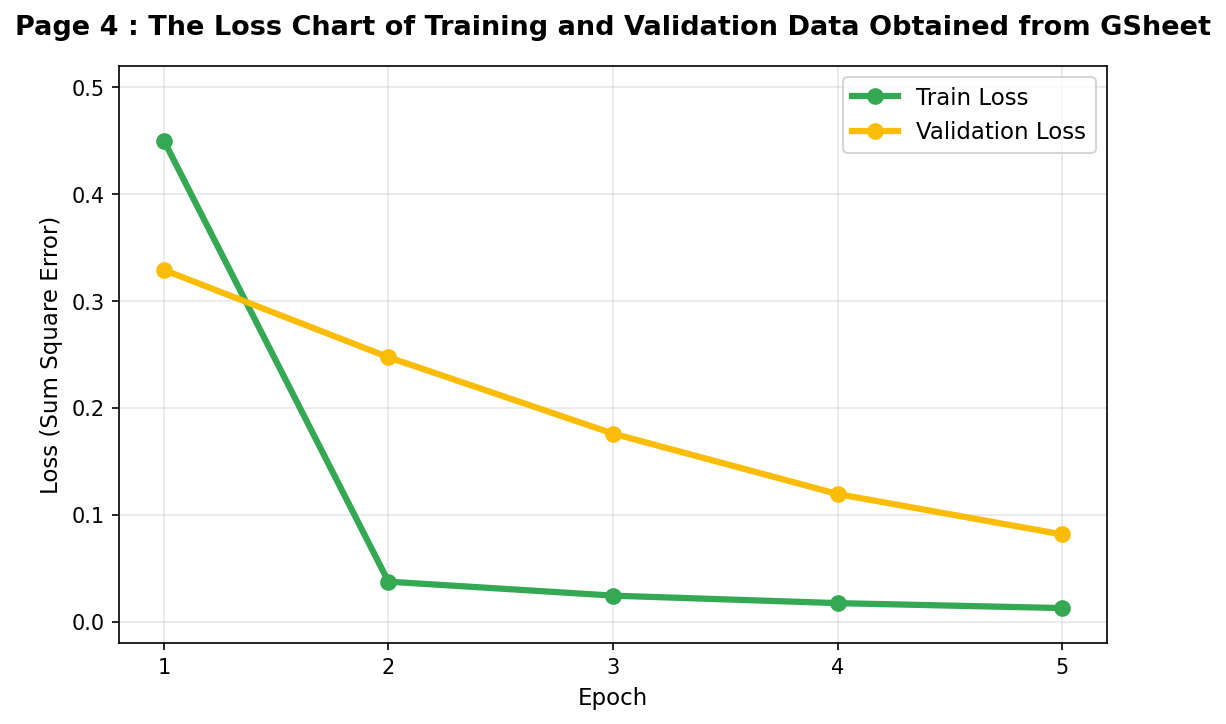

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5))

ax.plot(epochs, summary_df['Train Loss'], marker='o', linewidth=3, markersize=7, color='#34A853', label='Train Loss')
ax.plot(epochs, summary_df['Validation Loss'], marker='o', linewidth=3, markersize=7, color='#FBBC05', label='Validation Loss')

ax.set_title('Page 4 : The Loss Chart of Training and Validation Data\nObtained from GSheet / Spreadsheet', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Epoch', fontsize=11)
ax.set_ylabel('Loss (Sum Square Error)', fontsize=11)
ax.set_xticks(epochs)
ax.set_ylim(-0.02, 0.52)
ax.grid(True, linestyle='-', alpha=0.3)
ax.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.savefig('page4_gsheet_loss.png', dpi=300, bbox_inches='tight')
plt.show()
